# From produced water to lithium carbonate: the sodium-saponified HBTA/TOPO process

This notebook builds and solves a whole process, from raw oilfield produced water to lithium carbonate, with the IDAES
and PrOMMiS process-modeling tools: softening, countercurrent solvent extraction closed by ePC-SAFT equilibrium, scrub,
strip, acid recovery, neutralization, organic reuse, carbonation and operating cost. It accompanies the produced-water
process study of the Lithium_Extraction project and its process explorer app.

**Runtime:** about 2 minutes. Run the cells in order, top to bottom. Each cell does one step of the simulation and
shows its result, like stepping through a process simulator.

**How to run.** Set up the environment once as described in [README.md](README.md): a conda environment with
Python 3.13, the ePC-SAFT Engine and Reaktoro, with this PrOMMiS checkout installed in it. Then start `jupyter lab` in
this folder, open this notebook and choose *Run All*. To run it without opening it:

```sh
jupyter nbconvert --to notebook --execute --inplace lithium_produced_water_process.ipynb
```
**As an app.** `voila lithium_produced_water_process.ipynb` (after `pip install voila`) serves this notebook as a web page that shows only the text, widgets and results, with the code hidden; it runs every cell when the page opens.

The helper functions called below live in `tutorial_tools/` in this folder. Each takes the model `m` and does one
job that would otherwise bury the flowsheet steps: writing constraints, starting points, figures and checks. The Lithium model code they call is in
`lithium_extraction/` and `analyses/`.

## Learning outcomes

- Build a countercurrent extraction train from the PrOMMiS `SolventExtraction` unit, closed by ePC-SAFT equilibrium
- Add scrub, strip, acid recovery, neutralization, organic reuse and lithium carbonate precipitation with IDAES and
  PrOMMiS unit models connected by Arcs
- Check the degrees of freedom, initialize and solve the whole process
- Read the cost per kg of lithium and the break-even lithium carbonate price from an IDAES costing block
- Check the solved process against the study's retained campaign
- Explore the process options of the process explorer app with widgets and compare them

## Problem statement

Oilfield produced water is the salty water that comes up with oil and gas. Some of it carries lithium at tens to a
few hundred milligrams per litre, alongside much more sodium, calcium and magnesium. The study asks **what a
continuous solvent-extraction process would cost to run on measured produced waters, and at what lithium carbonate
price it would cover that cost.**

![Block flow diagram of the process](figures/produced_water_process_block_flow_diagram.png)

*Block flow diagram from the manuscript (Figure 1). This notebook follows the upper lane, sodium-saponified HBTA/TOPO with
whole-water softening.*

The process has five steps:

1. **Softening.** Sodium hydroxide and soda ash precipitate magnesium and calcium as sludge; hydrochloric acid then
   brings the water to an assumed process pH of 5.77.
2. **Extraction.** The softened water flows against an organic liquid through countercurrent mixer-settler stages.
   The organic holds HBTA with TOPO in a kerosene-like diluent, with 70 % of the HBTA in its sodium (saponified) form,
   so it trades sodium rather than acid for lithium.
3. **Scrub.** A dilute hydrochloric acid wash removes most of the sodium the organic picked up, losing some lithium.
4. **Strip.** Stronger hydrochloric acid moves the lithium into a small volume of water, the strip liquor. Most unused
   acid is recovered and the rest neutralized. The organic is re-saponified and reused; a small part is lost and
   replaced each pass.
5. **Carbonation.** Soda ash precipitates lithium carbonate (Li$_2$CO$_3$), the product, from the concentrated strip
   liquor. Most of the mother liquor is recycled; a purge removes salt.

**The case solved here.** 1 m$^3$/h of MS-2 water at base-case prices, with the design the study's optimization accepted
for it (5 extraction stages, 0.10 mol/L HBTA with equal TOPO, O/A = 1, 70 % saponified). The design is fixed, so the
flowsheet is solved once as a simulation. The Mars Hill water is then solved at its own accepted design. The operating
cost counts reagents, extractant and diluent replacement, and sludge disposal; it excludes energy, capital and labor.

### Glossary

| Term | Meaning |
|---|---|
| HBTA, TOPO | benzoyltrifluoroacetone (the extractant that binds lithium) and trioctylphosphine oxide (its partner in the organic) |
| saponified | extractant pre-reacted with sodium hydroxide, so it exchanges sodium, not acid, for lithium |
| NaOH, Na$_2$CO$_3$, HCl | sodium hydroxide, soda ash, hydrochloric acid (priced as a 31 wt% solution) |
| LCE | lithium carbonate equivalent: 1 kg of lithium makes 5.32 kg of Li$_2$CO$_3$ |
| O/A | organic-to-aqueous flow ratio |
| raffinate | the water leaving the last extraction stage |
| MS-2, Mars Hill | USGS Smackover produced-water samples from Arkansas (wells MSPU 4-W1 and Cornelius 1) |
| ePC-SAFT, Engine | the thermodynamic model of each extraction stage, and the project's pinned library that evaluates it |
| Arc | a connection that equates the outlet port of one unit with the inlet port of the next |

## Step 1: Import the tools

The IDAES and PrOMMiS pieces of the flowsheet, the Lithium modules that write the downstream units, and the
tutorial helpers.

In [1]:
from idaes.core import FlowDirection, FlowsheetBlock
from idaes.core.util.model_statistics import degrees_of_freedom
from prommis.solvent_extraction.solvent_extraction import SolventExtraction
from pyomo.environ import ConcreteModel, value

import tutorial_tools as tools
from tutorial_tools import produced_water_process as pw
from lithium_extraction.prototypes.produced_water_sx_prototype import chain, costing, downstream, set_c, stage
from lithium_extraction.prototypes.produced_water_sx_prototype.stage import ExtentReactions, MolarFlowParameters

In [2]:
tools.versions()

,version
ePC-SAFT Engine,1.2.0 (source commit 4cb87490)
IDAES,2.13.0
PrOMMiS,1.1.0+gc36e5836c
Pyomo,6.10.1


## Step 2: Inputs

### 2.1 The waters and their accepted designs

Each water is one measured USGS sample. The calcium and magnesium per kilogram of lithium set most of the softening
cost. The study's campaign optimized each water over 1 to 5 extraction stages and 0.1 to 0.4 mol/L HBTA, at O/A = 1 and
70 % saponification, requiring at least 95 % lithium extraction. The design kept for each water is the cheapest,
with ties within 0.1 % going to fewer stages (`results/targets/exchange_band.json`).

In [3]:
pw.waters()

,Li (mg/L),Na (mg/L),Ca (mg/L),Mg (mg/L),Cl (mg/L),(Ca+Mg)/Li (kg/kg),accepted stages,HBTA (mol/L organic),O/A,saponified fraction
MS-2,168,"64,100","36,900","3,310","174,000",239,5,0.1,1,0.7
Mars Hill,423,"72,500","29,300","2,243","176,679",74.6,5,0.112,1,0.7


### 2.2 Softening

Softening precipitates the hardness ions with fixed doses per litre of raw water:

$$
\mathrm{Mg^{2+} + 2\,OH^- \longrightarrow Mg(OH)_{2(s)}},
\qquad n_{NaOH} = 2.4\, n_{Mg}
$$

$$
\mathrm{M^{2+} + CO_3^{2-} \longrightarrow MCO_{3(s)}},\quad \mathrm{M = Ca, Sr, Ba},
\qquad n_{Na_2CO_3} = 1.2\,(n_{Ca} + n_{Sr} + n_{Ba})
$$

then hydrochloric acid brings the water to pH 5.77, an assumption adopted from MS-2 for every water. Each precipitate
is filtered as a cake holding 70 % liquid by mass and washed with one volume of water per volume of cake liquid; the
lithium in the liquid the cake keeps is the softening loss.

The geochemistry library Reaktoro solves each dose. `pw.soften` runs the softening script
(`analyses/prototypes/modular_process/scripts/run_softening.py`) as a subprocess, exactly as the campaign did.

In [4]:
softened = {site: pw.soften(site) for site in pw.WATERS}
pw.softening_table(softened)

,NaOH (kg/m3 raw),soda ash (kg/m3 raw),"HCl, 31% (kg/m3 raw)",wet sludge (kg/m3 raw),softened water (L per L raw),Ca+Mg left (mg/L),Li kept in softened water (%)
MS-2,13.1,120,36.4,342,1.02,0.0627,92.8
Mars Hill,8.86,96.3,28.6,273,1.01,0.069,94.3


## Step 3: The extraction chemistry

Steps 3 to 9 solve the lead case, MS-2. Inside the extraction stages, flows are mol/h at 1 L/h of softened water; the
downstream units use 1 L/h of raw water, and $v$ (litres of softened water per litre of raw water) converts between
them.

With HBTA written HA, TOPO written T and M = Li or Na, each stage reaches equilibrium in three reactions:

$$
\mathrm{M^+_{(aq)} + HA_{(org)} + T_{(org)} \;\rightleftharpoons\; MA{\cdot}T_{(org)} + H^+_{(aq)}}
\qquad \text{(R1: M = Li, R2: M = Na)}
$$

$$
\mathrm{HA_{(org)} \;\rightleftharpoons\; H^+_{(aq)} + A^-_{(aq)}} \qquad \text{(R5: HBTA dissolving into the water)}
$$

Subtracting R2 from R1 gives the sodium-for-lithium exchange that the saponified organic performs:
$\mathrm{Li^+_{(aq)} + NaA{\cdot}T_{(org)} \rightleftharpoons LiA{\cdot}T_{(org)} + Na^+_{(aq)}}$. ePC-SAFT supplies the
activities, and each reaction is at equilibrium when $\sum_{p,i}\nu_{r,pi}\ln a_{pi} = \ln K_r$, with the Li/Na
exchange constant from the single-stage fit.

`pw.starting_profile` first solves the stages one at a time with the Engine, sweeping until the organic leaving each
stage stops changing. That profile is the flowsheet's starting point, and it tells which reactions are active in each
stage: water autoprotolysis ($\mathrm{H_2O \rightleftharpoons H^+ + OH^-}$) matters only in some. `pw.stage_chemistries`
compiles one Engine record per stage for its active reactions.

In [5]:
site = 'MS2'
water = softened[site][pw.CASE]
v = water['feed_l']  # L softened water per L raw water
start = pw.starting_profile(site, softened)
chemistries = pw.stage_chemistries(site, start)
print(f'{len(chemistries)} stages, {len(set(map(id, chemistries)))} Engine record(s); v = {v:.4f}')

5 stages, 1 Engine record(s); v = 1.0152


## Step 4: Build the extraction stages

### 4.1 Model, property packages and transfer extents

As in every IDAES model, a Pyomo `ConcreteModel` holds a steady-state `FlowsheetBlock`. Each phase gets a molar-flow
property package. In each stage $k$ the transfer extents $\boldsymbol\xi_k$ conserve lithium, sodium,
exchangeable hydrogen and total BTA:

$$
\mathbf n^{out}_k = \mathbf n^{in}_k + \mathbf N\,\boldsymbol\xi_k, \qquad \mathbf C\,\mathbf N = \mathbf 0 .
$$

In [6]:
m = ConcreteModel()
m.fs = FlowsheetBlock(dynamic=False)
m.fs.aqueous_properties = MolarFlowParameters(phase='aqueous', species=set_c.SUPPORTS[0])
m.fs.organic_properties = MolarFlowParameters(phase='organic', species=set_c.SUPPORTS[1])
m.fs.extents = ExtentReactions(stoichiometry=tools.extent_stoichiometry(chemistries[0]))

### 4.2 The extraction unit

One PrOMMiS `SolventExtraction` unit holds all the stages: water flows forward from stage 1, organic backward from
the last stage. `label_streams` names the feeds `m.fs.boundary[s]` and the stage outlets `m.fs.stage[k].outlet[s]`,
and records $v$.

In [7]:
m.fs.extraction = SolventExtraction(
    number_of_finite_elements=len(chemistries),
    heterogeneous_reaction_package=m.fs.extents,
    aqueous_stream={'property_package': m.fs.aqueous_properties, 'flow_direction': FlowDirection.forward},
    organic_stream={'property_package': m.fs.organic_properties, 'flow_direction': FlowDirection.backward},
)
tools.label_streams(m, v)

### 4.3 Equilibrium in every stage

The Engine closes each stage, one equation per independent species:

$$
n^{out}_{s,k} = \mathcal E_s\!\left(\mathbf n^{in}_k;\ T, P\right).
$$

Two more conditions keep the Engine record consistent: the TOPO it counts follows the extractant,
$n_{T,total} = \mathrm{O/A}\cdot c$, and no stage may leave negative free HBTA or TOPO.

In [8]:
tools.add_stage_equilibrium(m, chemistries)
pw.add_extractant_inventory(m, site)

### 4.4 Feeds

The softened water and the fresh organic entering the stages, per litre of softened water. The organic is 0.10 mol/L
HBTA with equal TOPO in diluent, with 70 % of the HBTA in its sodium form.

In [9]:
pw.feed_extraction(m, site, water)

,softened water,fresh organic
mmol per L of softened water,,
water,"55,508",0
lithium-cation,22.1,0
sodium-cation,"4,931",0
hydrogen-cation,0.00169,0
hydroxide-anion,0,0
bta-anion,0,0
chloride-anion,"4,954",0
hbta,0,30
topo,0,30


### 4.5 The design and the degrees of freedom

`pw.add_design` adds the three design variables, O/A, the HBTA concentration $c$ and the saponified fraction
$r_{Na}$, as fixed variables, and writes the fresh-organic feed in terms of them (per litre of softened water):

$$
n_{HA,in} = n_{T,in} = \mathrm{O/A}\cdot c\,(1 - r_{Na}), \qquad
n_{NaA{\cdot}T,in} = \mathrm{O/A}\cdot c\, r_{Na}.
$$

In the campaign's optimization these variables were released and IPOPT minimized the cost; here they stay fixed, so
the solve is a simulation and the model must be square.

In [10]:
fixed = pw.add_design(m, site, water)
assert degrees_of_freedom(m) == 0
fixed

,value
organic_to_aqueous_ratio,1
extractant_mol_l,0.1
saponification_ratio,0.7


## Step 5: Initialize and solve the extraction stages

As in the IDAES tutorials, one part is solved before the connected flowsheet. `stage.initialize` loads the starting
profile into every stage and sets the extents from the balances. IPOPT then solves the stages together (exact second
derivatives, tight tolerances, optimality conditions checked from the log), and `pw.check_extraction` solves every
stage again on its own with the Engine: the flowsheet outlets must agree within $10^{-9}$ mol/L, and each stage must
keep the reactions its Engine record was compiled for.

In [11]:
stage.initialize(m, pw.stage_amounts(start))
pw.solve(m, 'MS2_extraction')['kkt']

{'stationarity': 0.0,
 'complementarity': 0.0,
 'feasibility': 1.4210854715202004e-14,
 'multiplier_sign': 0.0}

In [12]:
extraction = pw.check_extraction(m)
print(f'Lithium extraction: {100 * value(m.fs.design.li_extraction):.2f} % of the softened water\'s lithium')
m.fs.extraction.report()

Lithium extraction: 99.56 % of the softened water's lithium

Unit : fs.extraction                                                       Time: 0.0
------------------------------------------------------------------------------------
    Unit Performance


------------------------------------------------------------------------------------
    Stream Table
                                      Units       aqueous Inlet  aqueous Outlet  organic Inlet  organic Outlet
    flow_mol_comp water            dimensionless       55.508          55.508             -               -   
    flow_mol_comp lithium-cation   dimensionless     0.022135      9.8199e-05             -               -   
    flow_mol_comp sodium-cation    dimensionless       4.9315          4.9572             -               -   
    flow_mol_comp hydrogen-cation  dimensionless   1.6923e-06      4.1811e-10             -               -   
    flow_mol_comp chloride-anion   dimensionless       4.9536          4.9536            

epcsaft_equilibrium prepared record 1


## Step 6: Choose the downstream alternative

Two choices are discrete: whether the scrub acid is set by its source ratio or by the stoichiometric demand of the
metals it removes, and which interval of the measured lithium carbonate solubility table the carbonation salt level
falls in. Every combination is checked before the solve (enough strip acid, a salt level inside the measured data);
the first admissible one is used. `pw.downstream_accounts` then computes the closed-form material balance and prices
of the downstream steps, used to start the units and to price them.

In [13]:
candidate, alternatives = pw.downstream_alternatives(m, site, softened)
assumptions, accounts = pw.downstream_accounts(m, site, candidate)
alternatives

scrub acid set by,source,stoichiometric
NaCl interval (mol/kg),,
0 to 0.1,,
0.1 to 0.2,,
0.2 to 0.5,,
0.5 to 1,,
1 to 1.5,,
1.5 to 2,,
2 to 2.5,selected,
2.5 to 3,,


## Step 7: Add the downstream units

### 7.1 Scrub and strip

Two single-stage PrOMMiS `SolventExtraction` units. Their transfer is a measured fraction of the metal held by the
entering organic, not an equilibrium calculation. In each, a complex gives its metal to the acid and frees its HBTA
and TOPO:

$$
\mathrm{MA{\cdot}T_{(org)} + H^+_{(aq)} \longrightarrow M^+_{(aq)} + HA_{(org)} + T_{(org)}},
\qquad n_{M,aq}^{out} = f_M\, n_{M,org}^{in}
$$

- scrub: 1 mol/L HCl at one tenth of the organic flow; $f_{Na} = 0.90$, $f_{Li} = 0.10$ (base case);
- strip: 2.5 mol/L HCl at one tenth of the organic flow; $f_{Li} = 0.95$ (Zhang et al. 2017, Fig. 6), $f_{Na} = 1$.

The scrub takes the loaded organic leaving stage 1 (scaled by $v$ to raw water), and an Arc carries the scrubbed
organic to the strip.

In [14]:
pw.add_scrub_and_strip(m, assumptions, candidate, accounts)
tools.unit_models(m)

,model class,ports
unit,,
extraction,SolventExtraction,"aqueous_inlet, aqueous_outlet, organic_inlet, ..."
scrub.unit,SolventExtraction,"aqueous_inlet, aqueous_outlet, organic_inlet, ..."
strip.unit,SolventExtraction,"aqueous_inlet, aqueous_outlet, organic_inlet, ..."


### 7.2 Acid recovery, neutralization and concentration

A `Separator` returns 90 % of the unused strip acid. A `Translator` moves the liquor into a WaterTAP aqueous
package, a `Mixer` adds one NaOH per remaining H⁺ ($\mathrm{H^+ + OH^- \to H_2O}$), and a `Separator` concentrates
the liquor to 1 mol Li per kg of water, returning the removed water to the strip. The strip-water volume is one tenth
of the organic, $\mathrm{O/A}\cdot v/10$ litres per litre of raw water.

In [15]:
downstream.liquor_properties(m.fs)
concentrate = chain.aqueous(m.fs, assumptions, m.fs.design.organic_to_aqueous_ratio * v, m.fs.strip.metals['Li'])

### 7.3 Organic reuse

Translators and separators count the stripped organic, send the lithium still on it out, lose 1 % of the organic
per pass, and add fresh HBTA, TOPO and diluent for the loss and for the HBTA dissolved into the raffinate. A
single-stage `SolventExtraction` re-saponifies 70 % of the HBTA:
$\mathrm{HA_{(org)} + T_{(org)} + Na^+_{(aq)} + OH^-_{(aq)} \to NaA{\cdot}T_{(org)} + H_2O}$. The prepared organic is
checked against the extraction's organic feed after the solve; there is no recycle Arc into the extraction.

In [16]:
chain.organic(m.fs, m, assumptions, v, 'hbta')

### 7.4 Carbonation

A `Mixer` joins the concentrate, soda ash and recycled mother liquor; the PrOMMiS `Precipitator` forms the product at
70 °C; a `Separator` recycles 90 % of the mother liquor and purges 10 %:

$$
\mathrm{2\,Li^+ + CO_3^{2-} \longrightarrow Li_2CO_{3(s)}}, \qquad
n_{Li,mother} = 2\, s(m_{NaCl})\, W, \qquad
s(m_{NaCl}) = s_0 + (s_1 - s_0)\,\frac{m_{NaCl} - m_0}{m_1 - m_0} ,
$$

where $W$ is the mother-liquor water (kg) and $s$ the Li$_2$CO$_3$ solubility, interpolated in Ge et al. (2025)
Table 4 inside the measured NaCl interval $[m_0, m_1]$ chosen in Step 6; soda ash leaves 0.5 mol/kg excess carbonate.
This call also expands every Arc into equality constraints (`network.expand_arcs`).

In [17]:
downstream.connect(m.fs, concentrate, assumptions, candidate, accounts)
tools.unit_models(m)

,model class,ports
unit,,
extraction,SolventExtraction,"aqueous_inlet, aqueous_outlet, organic_inlet, ..."
acid_recovery,Separator,"inlet, recovered, liquor"
strip_liquid,Translator,"inlet, outlet"
neutralization,Mixer,"acid, caustic, outlet"
neutral_projection,Translator,"inlet, outlet"
concentration,Separator,"inlet, concentrate, recycle"
regeneration,Translator,"inlet, outlet"
regenerated,Separator,"inlet, organic, lithium_discharge"
organic_loss,Separator,"inlet, retained, loss"


The Arcs that connect the units:

In [18]:
tools.arcs(m)

,from,to
arc,,
strip.scrubbed_organic,scrub.unit.organic_outlet,strip.unit.organic_inlet
acid_recovery.feed,strip.unit.aqueous_outlet,acid_recovery.inlet
strip_liquid.feed,acid_recovery.liquor,strip_liquid.inlet
neutralization.feed,strip_liquid.outlet,neutralization.acid
neutral_projection.feed,neutralization.outlet,neutral_projection.inlet
concentration.feed,neutral_projection.outlet,concentration.inlet
regeneration.feed,strip.unit.organic_outlet,regeneration.inlet
regenerated.feed,regeneration.outlet,regenerated.inlet
organic_loss.feed,regenerated.organic,organic_loss.inlet


### 7.5 Initialize the downstream units

The units downstream of extraction are solved in sequence, block by block (Pyomo's
`solve_strongly_connected_components`), with the extraction held at its solution; the carbonation recycle loop
starts from its closed-form balance.

In [19]:
pw.initialize_downstream(m, assumptions, accounts)

### 7.6 Costing

An IDAES `FlowsheetCostingBlock` registers one flow per priced item. At 1 m$^3$/h of raw water,

$$
C_{op} = \sum_j p_j\, \dot m_j \ \ [\mathrm{USD/m^3}], \qquad
C_{Li} = \frac{C_{op}}{\dot m_{Li}} \ \ [\mathrm{USD/kg\ Li}], \qquad
P_{LCE}^{\,\text{break-even}} = \frac{C_{Li}}{5.32} .
$$

`pw.priced_flows` lists each item's mass flow (from the units above, or fixed softening amounts) with its price, and
the lithium leaving in the product.

In [20]:
flows, lithium_kg_h = pw.priced_flows(m, accounts)
costing.attach(m.fs, flows, lithium_kg_h)
degrees_of_freedom(m)

0

## Step 8: Solve the whole process

One IPOPT solve now covers extraction, scrub, strip, acid recovery, neutralization, concentration, organic reuse,
carbonation and costing. `pw.whole_process_result` then checks the solution independently. It re-solves every stage
with the Engine, recomputes the closed-form balances and costs (every connected unit must match within $10^{-9}$),
checks that the prepared organic equals the extraction organic feed, closes the Li, Na, Ca, carbonate and BTA
balances of the whole process, and requires every inequality to hold. The design must then meet every process
requirement (95 % lithium extraction, organic loading).

In [21]:
pw.solve(m, 'MS2_whole_process')['kkt']

{'stationarity': 0.0,
 'complementarity': 0.0,
 'feasibility': 2.842170943040401e-14,
 'multiplier_sign': 0.0}

In [22]:
result = pw.whole_process_result(m, site, softened)

## Step 9: Results for MS-2

### 9.1 Recovery and cost

Lithium extraction is the share of the softened water's lithium the organic takes up; recovery is the share of the
raw water's lithium that ends in the lithium carbonate.

In [23]:
pw.headline(m, result, softened, site)

Li extraction (%)                        99.6
Li recovery to Li2CO3 (%)                69.2
Li2CO3 product (kg per m3 raw water)    0.619
operating cost (USD per m3 raw water)     220
operating cost (USD per kg Li)          1,894
break-even price (USD per kg LCE)         356
Name: MS-2, dtype: float64

### 9.2 Unit reports

Every IDAES unit model has a `report()`. Flows are plain amounts: mol per litre of raw water in the downstream units.
The strip moves the lithium from the organic into the acid; free HBTA and TOPO return to the organic.

In [24]:
m.fs.strip.unit.report()


Unit : fs.strip.unit                                                       Time: 0.0
------------------------------------------------------------------------------------
    Unit Performance


------------------------------------------------------------------------------------
    Stream Table
                                      Units       aqueous Inlet  aqueous Outlet  organic Inlet  organic Outlet
    flow_mol_comp hydrogen-cation  dimensionless    0.25381          0.23018              -               -   
    flow_mol_comp lithium-cation   dimensionless     0.0000         0.019128              -               -   
    flow_mol_comp sodium-cation    dimensionless     0.0000        0.0044981              -               -   
    flow_mol_comp chloride-anion   dimensionless    0.25381          0.25381              -               -   
    flow_mol_comp lithium-carrier  dimensionless          -                -       0.020135       0.0010067   
    flow_mol_comp sodium-carrier   dim

### 9.3 Lithium through the process

Grams of lithium per m$^3$ of raw water, with the share of the raw water's lithium in brackets. Every loss leaves in
a named stream; the cell returns the closure, raw-water lithium minus product and all losses.

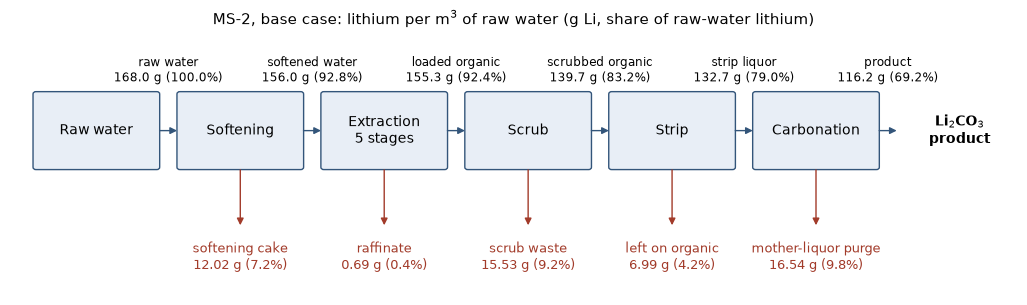

6.002143226879753e-16

In [25]:
pw.lithium_diagram(result, site)

### 9.4 Stream tables

Every physical stream in mmol per litre (mol per m$^3$) of raw water: aqueous and reagent streams by element or ion,
organic streams by species (`BTA_total` and `TOPO_total` count all HBTA and TOPO).

In [26]:
aqueous_streams, organic_streams = pw.stream_tables(result)
aqueous_streams

,Li,Na,K,Ca,Mg,Sr,Cl,H,OH,C,BTA,water
washed extraction feed,22.5,"5,007",54.6,0.000839,0.0012,0.000158,"4,944",296,,194,,"51,155"
physical raffinate,0.0997,"5,033",54.6,0.000839,0.0012,0.000158,"4,944",296,0.0181,194,3.69,"51,155"
saponification NaOH input,,71.1,,,,,,,71.1,,,
scrub HCl input,,,,,,,102,102,,,,
scrub waste,2.24,40.5,,,,,102,58.8,,,,
gross strip HCl input,,,,,,,254,254,,,,
recovered unused strip HCl,,,,,,,207,207,,,,
strip liquor before neutralization,19.1,4.5,,,,,46.6,23,,,,
regeneration lithium discharge,1.01,,,,,,,,,,,
neutralization NaOH input,,23,,,,,,,23,,,


In [27]:
organic_streams

,hbta,topo,lithium-carrier,sodium-carrier,diluent,BTA_total,TOPO_total,HBTA,TOPO
saponified organic input,30.5,30.5,0,71.1,"4,394",,,,
loaded organic,30.5,34.2,22.4,45,"4,394",,,,
organic loss,,,,,43.9,0.978,1.02,,
regenerated organic,,,,,"4,350",96.9,101,,
organic make-up input,,,,,43.9,,,4.67,1.02


### 9.5 Extraction stage profile

Lithium moves from the water into the organic stage by stage, while the saponified organic gives up its sodium. In
the species names, `lithium-carrier` and `sodium-carrier` are the LiA·T and NaA·T complexes. Amounts are mmol per litre
of softened water leaving each stage.

In [28]:
pw.stage_table(result)

,lithium-cation,sodium-cation,lithium-carrier,sodium-carrier,hbta,bta-anion
stage,,,,,,
1,10.9,"4,945",22,44.3,30,2.09
2,4.14,"4,952",10.8,57.6,30,2.88
3,1.37,"4,956",4.04,65.2,30,3.34
4,0.408,"4,957",1.27,68.4,30,3.55
5,0.0982,"4,957",0.31,69.6,30,3.64


### 9.6 Operating cost

Each item's cost is read from the costing block (`aggregate_flow_costs`) and divided by the lithium in the product.
HBTA replacement dominates: HBTA dissolves into the raffinate on every pass on top of the 1 % mechanical loss, and is
priced at a screening value of 100 USD/kg. Softening soda ash is second, because MS-2 carries about 240 kg of calcium
and magnesium per kg of lithium.

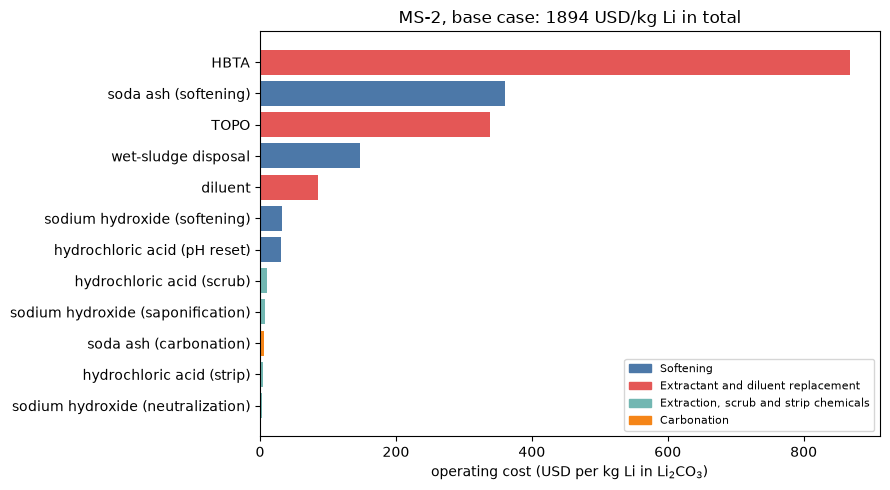

,USD/m3 raw water,USD/kg Li
step,,
Softening,66.4,572
Extractant and diluent replacement,150,"1,293"
"Extraction, scrub and strip chemicals",2.8,24.2
Carbonation,0.7,6.1


In [29]:
costs = pw.costs(m)
pw.plot_costs(costs, site, result['cost_usd_kg_li'])
costs.groupby('step', sort=False)[['USD/m3 raw water', 'USD/kg Li']].sum().round(1)

#### Price sensitivity

The prices are screening values. Scale each group of prices with the sliders to see how the operating cost and the
break-even price move. The flows stay at the solved design, so this is a price sensitivity, not a new optimization:
at other prices the cheapest design could change.

In [30]:
pw.price_sensitivity(m, result)

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='softening reagents', layout…

## Step 10: Mars Hill with the Lithium builders

`pw.run_water` solves another water at its own accepted design with the Lithium project's own flowsheet builders
(`set_c.build_flowsheet`, `optimization.decisions`, `full_process.connect_units`), which write the same units as
Steps 3 to 8. Agreement of both waters with the retained campaign in Step 12 checks the two builds against each other.

epcsaft_equilibrium prepared record 2


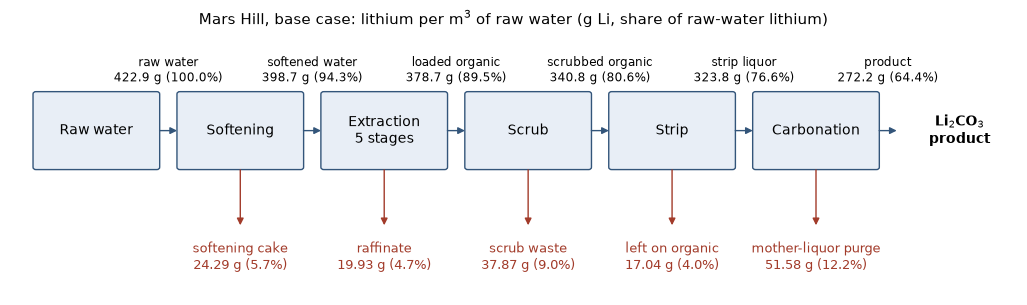

6.036837696399289e-16

In [31]:
results = {site: result}
mars_hill, results['MarsHill'] = pw.run_water('MarsHill', softened)
pw.lithium_diagram(results['MarsHill'], 'MarsHill')

## Step 11: Compare the two waters

### 11.1 Summary

In [32]:
pw.summary(results)

,MS-2,Mars Hill
extraction stages,5,5
HBTA (mol/L organic),0.1,0.112
Li extraction (%),99.6,95
Li recovery to Li2CO3 (%),69.2,64.4
Li2CO3 product (kg per m3 raw),0.619,1.45
operating cost (USD/kg Li),"1,894",733
operating cost (USD/m3 raw water),220,200
break-even price (USD/kg LCE),356,138


### 11.2 Stage profiles

The water enters stage 1 and leaves the last stage as raffinate; the organic flows the other way. Left: lithium left
in the water leaving each stage (log scale). Right: the lithium and sodium complexes in the organic leaving each stage.

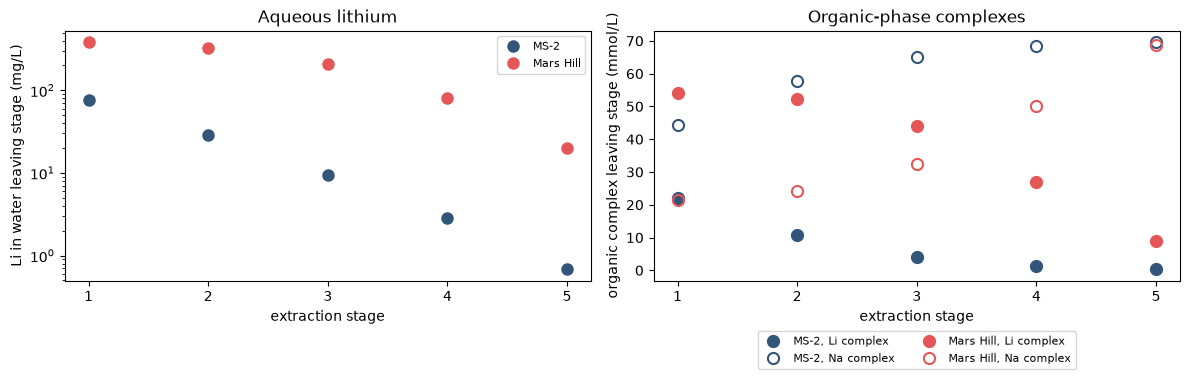

In [33]:
pw.plot_profiles(results)

### 11.3 Break-even lithium carbonate price

Both waters need a price far above the base (17.5 USD/kg LCE) and optimistic (20.9 USD/kg LCE) prices. Capital,
labor and energy, which are excluded, would raise these numbers further.

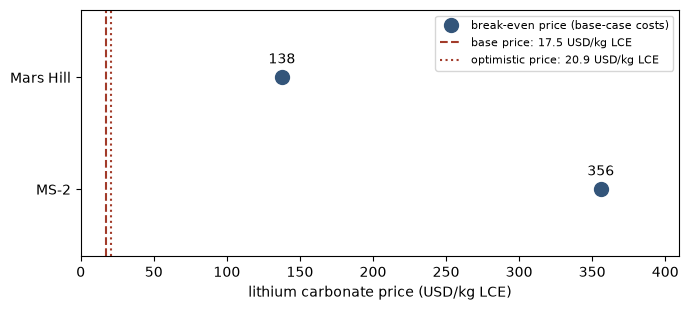

,break-even (USD/kg LCE),times base price,times optimistic price
MS-2,356,20.3,17
Mars Hill,138,7.87,6.59


In [34]:
pw.plot_break_even(results)

## Step 12: Check against the study's retained campaign

Every reproduced number is compared with the record the manuscript cites: the accepted design's campaign result
(`analyses/prototypes/modular_process/results/campaign/selected/`), the manuscript's summary table
(`results/targets/exchange_band.json`) and the retained softening result.

| Quantity | Limit |
|---|---|
| costs and break-even prices | relative $10^{-6}$ (cost items: $10^{-6}$ of the total) |
| extraction and recovery fractions, HBTA loss | absolute $10^{-9}$ |
| stage outlets and physical streams | absolute $10^{-9}$ mol per litre |
| softening result | relative $10^{-9}$, absolute $10^{-12}$ ($10^{-9}$ for the HCl dose and pH) |

The campaign ran on an earlier Engine build, so the first table shows both Engine commits: agreement also shows the
installed release leaves these results unchanged. The figure puts every comparison on one scale, its difference divided by its limit: a point below the red line is within its limit, and a difference of $10^{-12}$ of the limit or less (exact agreement included) sits on the bottom line. The cell stops with an error if any quantity is outside its limit; `checks` holds every line.

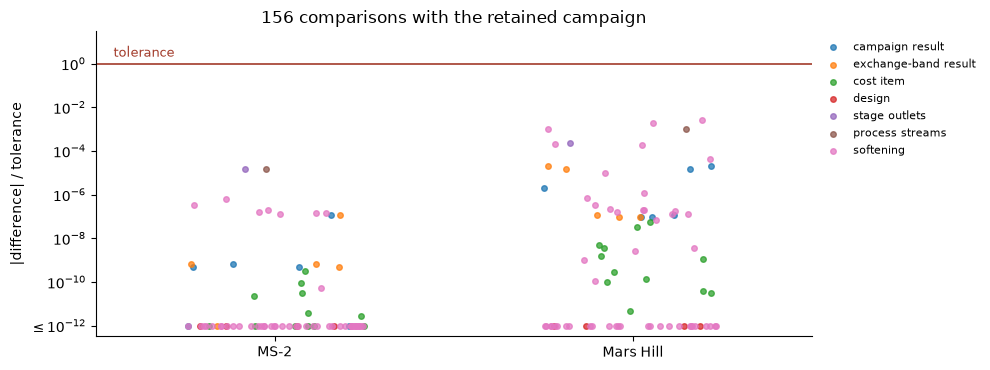

,comparisons,largest difference / tolerance,all within tolerance
MS-2,78,1.4e-05,✓
Mars Hill,78,2.7e-03,✓


In [35]:
pins, summary, checks = pw.check_campaign(results, softened)
summary

In [36]:
pins

,campaign Engine commit,this run
MS-2,0bec2bdf,4cb87490
Mars Hill,0bec2bdf,4cb87490


## Step 13: Explore the options

The process explorer app lets you pick a produced water, a price case, the lithium–sodium exchange fit, the number of
extraction stages, and whether to read the retained result or solve it again. The same choices are here as widgets.

- **produced water**: the four measured USGS Smackover samples;
- **price case**: base or optimistic reagent and product prices;
- **Li/Na exchange**: the single-stage fit (lead) or the cascade fit (sensitivity) of the exchange constant;
- **extraction stages**: 1 to 5;
- **calculation**: read the retained campaign result instantly; *solve the design* runs the whole process at the
  campaign's design for that choice; *optimize the design* lets IPOPT choose the HBTA concentration that minimizes
  the operating cost per kg of lithium, as the campaign did. A solve uses the app's own calculation in a separate
  process and takes from a few seconds to about five minutes.

Change the widgets, then run the cell below them; every run adds a row to the comparison. Widgets show only in a
running notebook opened with the command in "How to run" at the top.

In [37]:
options = pw.Options()
options

Options(children=(Dropdown(description='produced water', layout=Layout(width='620px'), options=(('MS-2', 'MS2'…

Run the current selection:

In [38]:
pw.run_selection(options)

,produced water,prices,Li/Na exchange,stages,calculation,result,HBTA (mol/L),Li extraction (%),Li to Li2CO3 (%),USD/m3 raw water,USD/kg Li,break-even (USD/kg LCE)
0,MS-2,base,single-stage fit,5,retained campaign result,optimized,0.1,99.6,69.2,220,"1,894",356


Start the comparison with the accepted design of every water at base prices and the single-stage fit, then compare
everything shown so far. Rerun this cell after each new selection to see it beside the others.

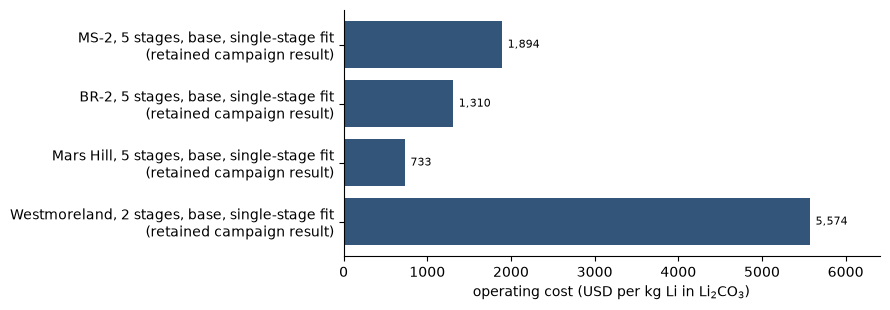

,produced water,prices,Li/Na exchange,stages,calculation,result,HBTA (mol/L),Li extraction (%),Li to Li2CO3 (%),USD/m3 raw water,USD/kg Li,break-even (USD/kg LCE)
0,MS-2,base,single-stage fit,5,retained campaign result,optimized,0.1,99.6,69.2,220,"1,894",356
1,BR-2,base,single-stage fit,5,retained campaign result,optimized,0.1,99.1,66.4,219,"1,310",246
2,Mars Hill,base,single-stage fit,5,retained campaign result,optimized,0.112,95,64.4,200,733,138
3,Westmoreland,base,single-stage fit,2,retained campaign result,optimized,0.1,97.4,73.8,481,"5,574","1,047"


In [39]:
pw.add_accepted_designs()

At their accepted designs, the cost per kg of lithium falls as the lithium in the water rises: Westmoreland (117 mg/L Li)
costs the most and Mars Hill (423 mg/L) the least, with MS-2 (168 mg/L) and BR-2 (252 mg/L) between. Westmoreland
costs the most even though it carries the least calcium and magnesium per kg of lithium.

## What the numbers mean, and their limits

- At base-case prices the MS-2 process recovers about 69 % of the raw water's lithium as lithium carbonate, at an
  operating cost near 1,900 USD/kg Li, so it needs about 356 USD/kg LCE to break even, against 17.5 to 20.9 USD/kg
  LCE. Mars Hill, with more lithium and less hardness per lithium, needs about 138 USD/kg LCE. HBTA replacement and
  softening soda ash are the largest costs.
- These are **model predictions**: ePC-SAFT equilibrium stages with exchange constants fitted to laboratory data on
  other solutions, laboratory scrub and strip fractions transferred to produced water, and measured lithium carbonate
  solubility. Nothing here was measured on these waters; there is no physical validation.
- Softening uses fixed reagent ratios; extractant prices and mechanical loss are screening assumptions, not quotes.
- The operating cost excludes energy, capital and labor, so the break-even prices are lower bounds.
- The agreement in Step 12 is **numerical reproduction** of the retained record, not a check against plant data.

**What is not rerun here.** The optimization over 1 to 5 stages and the extractant concentration (the campaign holds
664 candidate records), the other waters (BR-2, Westmoreland), the optimistic case, the cascade-fit sensitivity, the
D2EHDTPA/BuPhen process and the plant-costing screen are read from the record, not rerun.